# Effective alignment depth

## 1. Data acquisition

Use the fixed 73-assay human ProteinGym v1.3 input panel and its 66 raw alignments. The public bundle supplies only selected raw alignments and the accession/panel metadata in this workflow; no derived predictions, features or result tables are read from it. Individual DMS measurements and released AlphaMissense scores are independently acquired from their public sources. The full source manifest and every selected alignment checksum are below.


In [1]:
from pathlib import Path
from collections import Counter,defaultdict
from io import BytesIO
import os,sys,json,gzip,csv,re,hashlib,time,urllib.request,ssl,zipfile,math,platform
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']:os.environ[key]='1'
import numpy as np
import pandas as pd
from scipy.stats import spearmanr,wilcoxon
from sklearn.metrics import roc_auc_score,average_precision_score
from Bio.Align import substitution_matrices
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display,Image,Markdown
RAW=Path(os.environ.get('AM_RAW_INPUTS','am_public_inputs')).expanduser().resolve()
OUTPUT=Path('calculated_outputs').resolve();RAW.mkdir(parents=True,exist_ok=True);OUTPUT.mkdir(parents=True,exist_ok=True)
STARTED=time.time()
pd.set_option('display.max_colwidth',100)
def show_figure(fig):
    buffer=BytesIO();fig.savefig(buffer,format='png',dpi=150,bbox_inches='tight');display(Image(data=buffer.getvalue()))


In [2]:
# An optional shared raw archive directory avoids duplicate downloads.
archive_cache=Path(os.environ.get('AM_ARCHIVE_CACHE',RAW))
archive_candidate=archive_cache/'alphamissense-inputs.zip'
if archive_candidate.exists() and not (RAW/archive_candidate.name).exists():
    assert hashlib.sha256(archive_candidate.read_bytes()).hexdigest()=='9088ab792238292f8f1ec5587f95876e0951a06484795266362d51b12641228c'
    os.link(archive_candidate,RAW/archive_candidate.name)


In [3]:
SOURCES = [{'id': 'am_aa',
  'path': 'inputs/raw/AlphaMissense_aa_substitutions.tsv.gz',
  'url': 'https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz',
  'sha256': 'bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d',
  'bytes': 1207278510},
 {'id': 'proteingym_dms',
  'path': 'inputs/raw/DMS_ProteinGym_v1.3_substitutions.zip',
  'url': 'https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip',
  'sha256': '3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921',
  'bytes': 43021128},
 {'id': 'am_public_bundle',
  'path': 'alphamissense-inputs.zip',
  'url': 'https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/alphamissense-inputs.zip',
  'sha256': '9088ab792238292f8f1ec5587f95876e0951a06484795266362d51b12641228c',
  'bytes': 998791045},
 {'id': 'mmseqs',
  'path': 'am-original-linux-mmseqs.tar.gz',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/8207614f1c0dc8639f69da8ed43e05d625581032/reproduction/primary/alphamissense/payloads/am-original-linux-mmseqs.tar.gz',
  'sha256': 'd53b0855819fe80146d5748eee4548f9b2006ecd1dd9cb0bc71be45b6e20c0b2',
  'bytes': 8629845}]

def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def acquire(source):
    p=RAW/Path(source['path']).name
    if not p.exists():
        partial=p.with_name(p.name+'.notebook-part')
        req=urllib.request.Request(source['url'],headers={'User-Agent':'AlphaMissense-analysis/1.0'})
        # ProteinGym's server omits an intermediate certificate; exact archive
        # content is authenticated by the fixed SHA256 below.
        context=ssl._create_unverified_context() if 'marks.hms.harvard.edu' in source['url'] and source.get('sha256') else None
        with urllib.request.urlopen(req,timeout=180,context=context) as r,partial.open('wb') as f:
            while True:
                b=r.read(4*1024*1024)
                if not b:break
                f.write(b)
        if source.get('sha256') and sha256_file(partial)!=source['sha256']:raise ValueError('Download checksum mismatch: '+p.name)
        if source.get('bytes') and partial.stat().st_size!=source['bytes']:raise ValueError('Download size mismatch: '+p.name)
        partial.replace(p)
    h=sha256_file(p)
    if source.get('sha256') and h!=source['sha256']:raise ValueError('Input checksum mismatch: '+p.name)
    if source.get('bytes') and p.stat().st_size!=source['bytes']:raise ValueError('Input size mismatch: '+p.name)
    return dict(path=p.name,url=source['url'],sha256=h,bytes=p.stat().st_size)
source_receipts=[acquire(s) for s in SOURCES]
display(pd.DataFrame(source_receipts))


,path,url,sha256,bytes
0,AlphaMissense_aa_substitutions.tsv.gz,https://storage.googleapis.com/dm_alphamissense/AlphaMissense_aa_substitutions.tsv.gz,bc18d954a9aa6b9efab8e40d6d1912e32b774906cd3846a1f51066588e9c176d,1207278510
1,DMS_ProteinGym_v1.3_substitutions.zip,https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/DMS_ProteinGym_substitutions.zip,3a83766254ac9ac9984ec25cb73c6e010ea4418f5e35f143933e6b6e6473b921,43021128
2,alphamissense-inputs.zip,https://github.com/shreyjain11/SPECTRAagent/releases/download/notebook-inputs-2026-11-08-v1/alph...,9088ab792238292f8f1ec5587f95876e0951a06484795266362d51b12641228c,998791045
3,am-original-linux-mmseqs.tar.gz,https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/8207614f1c0dc8639f69da8ed43e05d625581...,d53b0855819fe80146d5748eee4548f9b2006ecd1dd9cb0bc71be45b6e20c0b2,8629845


In [4]:
MSA_CHECKSUMS = [{'filename': 'A4_HUMAN_2023-08-07_b01.a2m',
  'bytes': 4268632,
  'sha256': 'f265c710a9a2490e5c159a88357a1faf707cb1d39f2b302dad44bb374ea54ac7'},
 {'filename': 'ACE2_HUMAN_2023-10-12_b05.a2m',
  'bytes': 9398270,
  'sha256': '673bb72434d967b01ee48a2829d9821118bef09c716aa0dc08d3d3ce9f991a0f'},
 {'filename': 'ADRB2_HUMAN_full_11-26-2021_b03.a2m',
  'bytes': 91858322,
  'sha256': '7833630934c8ace16fbaa5d4fa16252d6b268079aa666ef325c26948d069068b'},
 {'filename': 'AICDA_HUMAN_2023-08-07_b01.a2m',
  'bytes': 4191187,
  'sha256': 'dbaa4ef2444170dd86d1171510a949dcd03a357e2ef8dde263817b518b76590c'},
 {'filename': 'B2L11_HUMAN_2023-08-07_b04.a2m',
  'bytes': 152522,
  'sha256': '9386cb5f2c2b28adca58b7df63fae7c4d787ec442b0ae5506e8a0402b791c4b3'},
 {'filename': 'BRCA1_HUMAN_full_11-26-2021_b02.a2m',
  'bytes': 1932751,
  'sha256': '58a954be6aafa52294f2eaf904bb2bc33cc3b511fe9b2777e41bdf8e5b65dfa5'},
 {'filename': 'BRCA2_HUMAN_2023-10-12_b01.a2m',
  'bytes': 3257301,
  'sha256': 'd50376efb43306890ff0394ca2329efdb2010d27b28fba521d24e9397645262f'},
 {'filename': 'CALM1_HUMAN_full_11-26-2021_b03.a2m',
  'bytes': 32118262,
  'sha256': 'ee5a63785f3d3414c241afd3a3d233956959d553c3ff1185665ad8383afa3d59'},
 {'filename': 'CAR11_HUMAN_2023-10-12_b02.a2m',
  'bytes': 1621364,
  'sha256': '80367077517d33bb375513946dd95fe35ff3f62bd25a7d3eb20b0b5260c48b69'},
 {'filename': 'CBPA2_HUMAN_2023-08-07_b03.a2m',
  'bytes': 1297356,
  'sha256': '2ffe3445ed93181ad0d0b4f430d246e4a986293fbd5f96588131d0dd51f1534b'},
 {'filename': 'CBS_HUMAN_2023-10-12_b08.a2m',
  'bytes': 11487977,
  'sha256': 'b49e7760d4c5d9d0580a603848a30bf139667cbd9338e7eeb6c1dfa364333a4e'},
 {'filename': 'CBX4_HUMAN_2023-08-07_b03.a2m',
  'bytes': 8815295,
  'sha256': '3b7c43b4015d0757e8396981760caf3d00a6e92d12936b3ce61a18d3cea789ad'},
 {'filename': 'CCR5_HUMAN_2023-08-07_b03.a2m',
  'bytes': 244616134,
  'sha256': 'f2c9feada5334d5bece3478767a098eed491447a38a1014ed979bf1a12cc5f05'},
 {'filename': 'CD19_HUMAN_2023-10-12_b01.a2m',
  'bytes': 701823,
  'sha256': 'cd206f99cda794f4ed02eef324245dd84d76e9398bd3ca4473c8a9db7c29c79c'},
 {'filename': 'CP2C9_HUMAN_full_11-26-2021_b04.a2m',
  'bytes': 139011917,
  'sha256': 'd8149e4af15272c450a424de95451c95f3059c6de1d2e87b81d9861bace692c1'},
 {'filename': 'DLG4_HUMAN_full_11-26-2021_b02.a2m',
  'bytes': 19388329,
  'sha256': 'bfb94d51c9248eadc80d5101ba35531ad6e107bc04354e6075aab98aee87ae63'},
 {'filename': 'DNJA1_HUMAN_2023-08-07_b07.a2m',
  'bytes': 26486638,
  'sha256': 'dba61097dafc8895a2f68859c616c3c03fabd08ad14caa7e690f1741225103c0'},
 {'filename': 'EPHB2_HUMAN_2023-08-07_b04.a2m',
  'bytes': 20883915,
  'sha256': 'dc88cac927cf1f26fd8a807ae6ce0b14e1c4b05ec23a3bf5cedcddd8f14b0d1f'},
 {'filename': 'ERBB2_HUMAN_2023-10-12_b02.a2m',
  'bytes': 10817475,
  'sha256': '0132f961bbae288bf6dc0b422d6710a7934aada14f9e8176807f023fbc6c38f5'},
 {'filename': 'FKBP3_HUMAN_2023-08-07_b03.a2m',
  'bytes': 327848,
  'sha256': '77a2a0eec8478379c78d4862c4adf3fe2c7e6a7b411c4f5b546d9ba7fbe67a49'},
 {'filename': 'GDIA_HUMAN_2023-10-12_b05.a2m',
  'bytes': 2500880,
  'sha256': 'dfbb738f12c99bf03b59a0f699d40ac3e670a8169b564cf4de0222cc44ef2d02'},
 {'filename': 'GRB2_HUMAN_full_11-26-2021_b05.a2m',
  'bytes': 8316320,
  'sha256': '052118b615bcf3dc54092215171bac2f9fae7df0da65fdff7565350da691f6fc'},
 {'filename': 'HEM3_HUMAN_2023-08-07_b02.a2m',
  'bytes': 23526425,
  'sha256': 'a15aa45172b488c755dd4f4a5e5eef77a2869a9bfade077ad0f237b5aebd28de'},
 {'filename': 'HMDH_HUMAN_2023-10-12_b05.a2m',
  'bytes': 2931263,
  'sha256': '32b0704fac589163afa730a99edb19e6e3e9e241d322998a993ac83efc61cbe6'},
 {'filename': 'HXK4_HUMAN_2023-08-07_b01.a2m',
  'bytes': 12100920,
  'sha256': '9693fc9b185db8668708c8bb55324ef3092209971e2457429064f35c86cb4239'},
 {'filename': 'HXK4_HUMAN_b0.1.a2m',
  'bytes': 11687650,
  'sha256': '45dd7ad98f3a2a6dae8f7d01d96304ce41219eb19f9a583139c09876abcc236b'},
 {'filename': 'KCNH2_HUMAN_535-565_11-26-2021_b05.a2m',
  'bytes': 877720,
  'sha256': '7cc728d34a1ae2f02aa4fc596ac4e394ebf42324d48c21c779f8f10167b264a4'},
 {'filename': 'LYAM1_HUMAN_2023-10-12_b04.a2m',
  'bytes': 1616490,
  'sha256': '74121ab74feb2f9e85e6580245ab09a24f582b0dd1f520538f70dceb786805c9'},
 {'filename': 'MET_HUMAN_2023-08-07_b09.a2m',
  'bytes': 59912882,
  'sha256': 'ee5147608ec09d7ffa721e84a7056fa436586d2bdfc1cb92ecbff0c5cf0b5cb5'},
 {'filename': 'MK01_HUMAN_full_11-26-2021_b06.a2m',
  'bytes': 49024511,
  'sha256': 'df6bf95cdfc92bfe3608fab7194baf9829fef2c3822dda14e6e8157a184d4104'},
 {'filename': 'MSH2_HUMAN_full_11-26-2021_b05.a2m',
  'bytes': 59713279,
  'sha256': 'f20174c63e61dcf168d79515b7b363393886861af0a0940cdb8dd8274802577c'},
 {'filename': 'MTHR_HUMAN_2023-08-07_b02.a2m',
  'bytes': 3316659,
  'sha256': 'b0bde44d3e73de4841a0b630f1378cd6fc897bfa3872370e47a94bda358b007d'},
 {'filename': 'NPC1_HUMAN_2023-10-12_b07.a2m',
  'bytes': 8388140,
  'sha256': '48565439454533642d576d20b05a2265fe8fc2a90a37e825cbfe4ee153c72154'},
 {'filename': 'NUD15_HUMAN_full_11-26-2021_b04.a2m',
  'bytes': 30259744,
  'sha256': '47fd19ec46527197e9d01f89658884b1f1fdacdaccab50e48abe2e6becb50bb4'},
 {'filename': 'OBSCN_HUMAN_2023-08-07_b02.a2m',
  'bytes': 70026269,
  'sha256': '815c8ec62ff4d0391c722b833cad9504617739b8c78f5b7b4a7e108159790a9c'},
 {'filename': 'OPSD_HUMAN_2023-10-12_b04.a2m',
  'bytes': 131017961,
  'sha256': 'e59bed6efebb809a97bcc843cef2a81ccdaae4810287585594bc9c3d8e1a62f6'},
 {'filename': 'OTC_HUMAN_2023-08-07_b02.a2m',
  'bytes': 52629696,
  'sha256': '1b4d329e089bd3ff16955c1cc43b0675f98a1f0b0f167b1c8815e3028717a678'},
 {'filename': 'OTU7A_HUMAN_2023-08-07_b02.a2m',
  'bytes': 99718391,
  'sha256': 'e4c011d6ecea17e4b5b1ea029cdf8a5a719c4edf377fb48217d1ef20930c495b'},
 {'filename': 'P53_HUMAN_full_11-26-2021_b09.a2m',
  'bytes': 1766669,
  'sha256': '77e82aff3a03c12b48b8f1a09235a103b7b80057be515e03d848d0f059c0226b'},
 {'filename': 'PAI1_HUMAN_2023-10-12_b05.a2m',
  'bytes': 22987149,
  'sha256': 'a76bd15ae4d4527c8d1cb9095599e9a67fb03cacf3ccd6d4d103e145145779cc'},
 {'filename': 'PIN1_HUMAN_2023-08-07_b02.a2m',
  'bytes': 17561914,
  'sha256': '5bcfaefef4169d889272993750e0af3836173ea0dfbae5d5cfcd448cfb6f4fa4'},
 {'filename': 'PPARG_HUMAN_2023-10-12_b04.a2m',
  'bytes': 21683437,
  'sha256': '0ff44715a174184dcfc49418aacc9ee6f793358c4c9deb1cee7e9cd3e2be7f4a'},
 {'filename': 'PPM1D_HUMAN_2023-10-12_b01.a2m',
  'bytes': 1184336,
  'sha256': '1576c007c6e3686bf430dc4c23c00a53190391e6fba6fd05d9bfa3e9df25ccb7'},
 {'filename': 'PR40A_HUMAN_2023-08-07_b03.a2m',
  'bytes': 6053160,
  'sha256': 'e8dbdd983c8d471178f83e3a6a15e0202a69cf1fe48fc527d2f4966490ae71f2'},
 {'filename': 'PRKN_HUMAN_2023-08-07_b05.a2m',
  'bytes': 729705,
  'sha256': 'dd825b85ed63ea4f2ea829bbd2208e2067465bfb0c1b3ea3a1530a7d0a6bd325'},
 {'filename': 'PTEN_HUMAN_full_11-26-2021_b01.a2m',
  'bytes': 8374923,
  'sha256': 'b173cfdebc7f5447d7f69d2bfb365ba87f316ae0b37dd99d73a92204247b52bd'},
 {'filename': 'RAF1_HUMAN_2023-10-12_b05.a2m',
  'bytes': 6661296,
  'sha256': '08cfbe8c06321a0f9a02394faf39c28b1e5e78f58d3eec53fa50679f745a7a28'},
 {'filename': 'RASH_HUMAN_full_11-26-2021_b03.a2m',
  'bytes': 45270483,
  'sha256': '000e4f612fa133c76d3f1f48950152fe4161b72887d7a51f2dad6081cdbb2f9c'},
 {'filename': 'RD23A_HUMAN_2023-08-07_b04.a2m',
  'bytes': 7644550,
  'sha256': '912e149ee64f8ccf23b67172eb98003bbb8e8e0825372c34cfebcdf9ac8da24b'},
 {'filename': 'S22A1_HUMAN_2023-08-07_b02.a2m',
  'bytes': 117270525,
  'sha256': 'eaaec0beac12bcd05d7c02b435356132835d9bb0ce7a08f5d6d1d9e53006cc2e'},
 {'filename': 'SC6A4_HUMAN_full_11-26-2021_b02.a2m',
  'bytes': 27344665,
  'sha256': '75dcf3392146dfe463d30270c684960271cd4e027ffee8e036b2c1a7bd592ce2'},
 {'filename': 'SCN5A_HUMAN_1611-1642_11-26-2021_b03.a2m',
  'bytes': 3264978,
  'sha256': 'de083d3aa2c62b9800a0736f54d060187e51645a604defdcafc105cb969f4b77'},
 {'filename': 'SERC_HUMAN_2023-08-07_b02.a2m',
  'bytes': 94104996,
  'sha256': '5b9426ecf356188a91ac29ab363af3952ccdfd83102f1835acec47561a738b48'},
 {'filename': 'SHOC2_HUMAN_2023-10-12_b04.a2m',
  'bytes': 13742998,
  'sha256': '0ffb4840aa821bf1aaccd35b22a6804d7d6f6cbee0818e73af26c0de14bcd747'},
 {'filename': 'SOX30_HUMAN_2023-08-07_b03.a2m',
  'bytes': 14011036,
  'sha256': '1bca6521fe499aca2cfa330259f8411fa9c5ee9ed82a3a46952b327fa4482ce1'},
 {'filename': 'SRC_HUMAN_2023-08-07_b06.a2m',
  'bytes': 21596537,
  'sha256': 'e7621daaa827721c8ae31d7df9de3ecbc7ead7c33497d497d8958594b9d5a312'},
 {'filename': 'SRC_HUMAN_full_11-26-2021_b06.a2m',
  'bytes': 15459508,
  'sha256': 'a25169b8794c090279790959fca2cca8310d55650597557074a673049bbbc370'},
 {'filename': 'SUMO1_HUMAN_full_11-26-2021_b02.a2m',
  'bytes': 11281749,
  'sha256': '231602b36affee5ebf58ccad63d870ba51f1fc88c8a68556fcf7f031c240f030'},
 {'filename': 'TADBP_HUMAN_full_11-26-2021_b09.a2m',
  'bytes': 543778,
  'sha256': '1d061f624a276613654af5ce19d2fc25a2e650e067fffb9b738b7780b4b06ca7'},
 {'filename': 'TPK1_HUMAN_full_11-26-2021_b02.a2m',
  'bytes': 5938159,
  'sha256': 'd85cf8edaffc686868f1c4ac5114e2f48c6f8de1f258205395b46c485c6a088a'},
 {'filename': 'TPMT_HUMAN_full_11-26-2021_b03.a2m',
  'bytes': 5431730,
  'sha256': 'a04d82fc1ebfe11ebdc26a5ffa12922adb18ebfd77f879a05178919def947e43'},
 {'filename': 'UBC9_HUMAN_full_11-26-2021_b03.a2m',
  'bytes': 13264098,
  'sha256': 'd95dc090b3e8951de91d60d950d21242d9725f3a5478e9bfe601ef674c1c9642'},
 {'filename': 'UBE4B_HUMAN_2023-08-07_b04.a2m',
  'bytes': 31000303,
  'sha256': '1017330409b543bd04fd07b592034c309fc79d8e98cf4531ce15ba6e11c7b6d5'},
 {'filename': 'UBR5_HUMAN_2023-08-07_b05.a2m',
  'bytes': 1617077,
  'sha256': '8807130f38daa1b18836d267a32c87f1d8973b79fa6a84a728308b283978b735'},
 {'filename': 'VKOR1_HUMAN_full_11-26-2021_b03.a2m',
  'bytes': 2835810,
  'sha256': '3ff3f21b0036d71055ab7754a483bcabc187bca4a1ae4159f0e98dca6a44da78'},
 {'filename': 'YAP1_HUMAN_full_11-26-2021_b02.a2m',
  'bytes': 867468,
  'sha256': 'e8657c1b34bee25bb357aaa94a65bd7851cea3c1ff7f4b408a53dee3cf68aedb'}]

import tarfile,shutil,subprocess
MSA=RAW/'primary_msas';MSA.mkdir(exist_ok=True)
# Copy only explicitly selected raw assets, never derived predictions or results.
with zipfile.ZipFile(RAW/'alphamissense-inputs.zip') as archive:
    panel_bytes=archive.read('am-primary/inputs/proteingym/kept_assays_verified.tsv')
    panel_metadata=pd.read_csv(BytesIO(panel_bytes),sep='\t')
    reference_path=RAW/'ProteinGym_selected_references.tar.gz'
    if not reference_path.exists():
        with archive.open('am-opus-r2/inputs/raw_references.tar.gz') as src,reference_path.open('wb') as dst:shutil.copyfileobj(src,dst,4*1024*1024)
assert sha256_file(reference_path)=='8079b9e63cbadbf928e09cf6124899a58062d056e40e9a0f5794b3fd25493f11'
expected={r['filename']:r for r in MSA_CHECKSUMS}
needed={name for name,r in expected.items() if not (MSA/name).exists() or sha256_file(MSA/name)!=r['sha256']}
if needed:
    with tarfile.open(reference_path,'r|gz') as archive:
        for member in archive:
            name=Path(member.name).name
            if not member.isfile() or name not in needed:continue
            with archive.extractfile(member) as src,(MSA/name).open('wb') as dst:shutil.copyfileobj(src,dst,4*1024*1024)
for name,r in expected.items():assert (MSA/name).stat().st_size==r['bytes'] and sha256_file(MSA/name)==r['sha256'],name
assert len(panel_metadata)==73 and set(panel_metadata.MSA_filename)==set(expected)
print('Verified raw inputs:',len(panel_metadata),'assays;',len(expected),'alignments')


Verified raw inputs: 73 assays; 66 alignments


In [5]:
assert platform.system()=='Linux' and platform.machine() in ['x86_64','AMD64'],'The pinned MMseqs executable requires Linux x86-64.'
MM=RAW/'mmseqs_fd711934753052544df18fa1dff8c762d6fe2188'
if not MM.exists():
    with tarfile.open(RAW/'am-original-linux-mmseqs.tar.gz','r:gz') as archive:
        with archive.extractfile('upstream_checks/bin/mmseqs') as src,MM.open('wb') as dst:shutil.copyfileobj(src,dst)
assert sha256_file(MM)=='c58e5b422092544aac95646828eb563cee32ca609c260c50a195bb560d24f2e6'
MM.chmod(MM.stat().st_mode|0o100)
assert subprocess.check_output([str(MM),'version'],text=True).strip()=='fd711934753052544df18fa1dff8c762d6fe2188'
MMSEQS_THREADS=int(os.environ.get('AM_MMSEQS_THREADS','8'))


## 2. Raw processing

Read the selected assay CSVs, keep standard single substitutions, and validate each wild-type amino acid against the assay target sequence. Parse every raw a2m alignment; lowercase insertions and match columns remain distinct.


In [6]:
assays={};dms_rows=[];qc=Counter()
with zipfile.ZipFile(RAW/'DMS_ProteinGym_v1.3_substitutions.zip') as archive:
    names={Path(n).name:n for n in archive.namelist() if n.endswith('.csv')}
    for meta in panel_metadata.to_dict('records'):
        aid=meta['DMS_id'];assays[aid]=meta
        table=pd.read_csv(archive.open(names[meta['DMS_filename']]))
        for row in table.itertuples():
            qc['DMS input rows']+=1;m=re.fullmatch(r'([ACDEFGHIKLMNPQRSTVWY])(\d+)([ACDEFGHIKLMNPQRSTVWY])',str(row.mutant))
            if not m:continue
            wt,pos,alt=m[1],int(m[2]),m[3]
            if not 1<=pos<=len(meta['target_seq']) or meta['target_seq'][pos-1]!=wt:qc['Reference mismatch']+=1;continue
            dms_rows.append({'assay':aid,'accession':meta['resolved_accession'],'msa':meta['MSA_filename'],'position':pos,'wt':wt,'alt':alt,'mutant':row.mutant,'fitness':float(row.DMS_score),'family':'Tsuboyama domains' if 'Tsuboyama' in aid else 'Other assays','msa_start':int(meta['MSA_start']),'msa_end':int(meta['MSA_end'])})
dms=pd.DataFrame(dms_rows);qc['Eligible DMS single substitutions']=len(dms)
display(pd.Series(qc,name='count').to_frame());display(dms.head())


,count
DMS input rows,374790
Eligible DMS single substitutions,273135


,assay,accession,msa,position,wt,alt,mutant,fitness,family,msa_start,msa_end
0,A4_HUMAN_Seuma_2022,P05067,A4_HUMAN_2023-08-07_b01.a2m,673,A,C,A673C,-1.018869,Other assays,1,770
1,A4_HUMAN_Seuma_2022,P05067,A4_HUMAN_2023-08-07_b01.a2m,673,A,D,A673D,-0.605052,Other assays,1,770
2,A4_HUMAN_Seuma_2022,P05067,A4_HUMAN_2023-08-07_b01.a2m,673,A,E,A673E,-0.590857,Other assays,1,770
3,A4_HUMAN_Seuma_2022,P05067,A4_HUMAN_2023-08-07_b01.a2m,673,A,F,A673F,-0.216833,Other assays,1,770
4,A4_HUMAN_Seuma_2022,P05067,A4_HUMAN_2023-08-07_b01.a2m,673,A,G,A673G,0.268496,Other assays,1,770


## 3. Axis and levels

Effective column depth sums sequence weights from fresh 80%-identity MMseqs clustering with 80% coverage (mode 1). A sequence weight is the reciprocal size of its assigned cluster. The notebook executes the pinned third-party binary directly; all analysis code remains in these cells. Occupancy is the raw non-gap fraction per match column. Map target residues using the alignment focus row and declared MSA start. Occupancy boundaries are 0.945, 0.987, 0.998 and 0.999, with insertions separate; depth boundaries are 2, 10, 50 and 200.


In [7]:
WEIGHTED=True
WITH_PSSM=False

AA='ACDEFGHIKLMNPQRSTVWY';AA_INDEX={a:i for i,a in enumerate(AA)}
REMOVE_INSERT=str.maketrans('','','abcdefghijklmnopqrstuvwxyz.')
REMOVE_GAPS=str.maketrans('','','abcdefghijklmnopqrstuvwxyz.-')
lookup=np.full(256,-1,dtype=int)
for i,a in enumerate(AA):lookup[ord(a)]=i
WORK=OUTPUT/'alignment_work';WORK.mkdir(exist_ok=True)
def aligned_rows(path):
    current=[]
    with path.open() as f:
        for line in f:
            if line.startswith('>'):
                if current:yield ''.join(current)
                current=[]
            else:current.append(line.strip())
        if current:yield ''.join(current)
def calculate_alignment(name,start):
    path=MSA/name;focus=None;n=0;fasta=WORK/'sequences.fa'
    if WEIGHTED:handle=fasta.open('w')
    for raw in aligned_rows(path):
        if focus is None:focus=raw
        if WEIGHTED:handle.write(f'>{n}\n{raw.translate(REMOVE_GAPS) or "X"}\n')
        n+=1
    if WEIGHTED:
        handle.close();result=WORK/'clusters';temporary=WORK/'temporary'
        command=[str(MM),'easy-cluster',str(fasta),str(result),str(temporary),'--min-seq-id','0.8','-c','0.8','--cov-mode','1','--threads',str(MMSEQS_THREADS),'-v','1']
        run=subprocess.run(command,capture_output=True,text=True)
        (OUTPUT/(name+'.mmseqs.log')).write_text(run.stdout+'\n'+run.stderr)
        if run.returncode:raise RuntimeError('MMseqs clustering failed for '+name+': '+run.stderr[-1000:])
        rep_of={};sizes=Counter()
        with Path(str(result)+'_cluster.tsv').open() as f:
            for line in f:
                rep,member=line.rstrip().split('\t');rep_of[int(member)]=rep;sizes[rep]+=1
        weights=np.array([1/sizes[rep_of[i]] if i in rep_of else 1. for i in range(n)])
    else:weights=None
    positions={};inserts=set();column=0
    for i,char in enumerate(focus):
        position=start+i
        if char.islower() or char=='.':inserts.add(position)
        else:positions[position]=column;column+=1
    occupancy=np.zeros(column);neff=np.zeros(column);counts=np.zeros((column,20)) if WITH_PSSM else None
    for i,raw in enumerate(aligned_rows(path)):
        text=raw.translate(REMOVE_INSERT);arr=np.frombuffer(text.encode('latin1')[:column],dtype=np.uint8)
        if arr.size<column:arr=np.r_[arr,np.full(column-arr.size,ord('-'),dtype=np.uint8)]
        nongap=arr!=ord('-');occupancy+=nongap
        if WEIGHTED:neff+=nongap*weights[i]
        if WITH_PSSM:
            ix=lookup[arr];valid=ix>=0;counts[np.flatnonzero(valid),ix[valid]]+=weights[i]
    occupancy/=n
    if WEIGHTED:
        for p in WORK.glob('clusters*'):
            if p.is_file():p.unlink()
        fasta.unlink();shutil.rmtree(temporary,ignore_errors=True)
    return {'positions':positions,'inserts':inserts,'occupancy':occupancy,'neff':neff,'counts':counts,'sequences':n,'global_neff':float(weights.sum()) if WEIGHTED else None}
features={};mapping=[]
msa_start=panel_metadata.groupby('MSA_filename').MSA_start.first().to_dict()
for i,name in enumerate(sorted(expected,key=lambda n:expected[n]['bytes']),1):
    began=time.time();features[name]=calculate_alignment(name,int(msa_start[name]));print(f'Alignment {i}/{len(expected)}: {name}, rows={features[name]["sequences"]}, seconds={time.time()-began:.1f}',flush=True)
for (aid,position),g in dms.groupby(['assay','position'],sort=False):
    meta=assays[aid];f=features[meta['MSA_filename']];position=int(position)
    if position in f['positions']:
        col=f['positions'][position];occupancy=round(float(f['occupancy'][col]),4);neff=round(float(f['neff'][col]),3) if WEIGHTED else np.nan;insertion=False
    elif position in f['inserts']:occupancy=neff=np.nan;insertion=True;col=None
    else:continue
    mapping.append({'assay':aid,'position':position,'occupancy':occupancy,'neff':neff,'insertion':insertion,'column':col})
position_features=pd.DataFrame(mapping);dms=dms.merge(position_features,on=['assay','position'],how='inner',validate='many_to_one')
dms['terminal']=(dms.position-dms.msa_start<20)|(dms.msa_end-dms.position<20)
display(position_features.describe(include='all'))


Alignment 1/66: B2L11_HUMAN_2023-08-07_b04.a2m, rows=660, seconds=3.7


Alignment 2/66: FKBP3_HUMAN_2023-08-07_b03.a2m, rows=3216, seconds=3.0


Alignment 3/66: TADBP_HUMAN_full_11-26-2021_b09.a2m, rows=1211, seconds=2.5


Alignment 4/66: CD19_HUMAN_2023-10-12_b01.a2m, rows=1183, seconds=4.6


Alignment 5/66: PRKN_HUMAN_2023-08-07_b05.a2m, rows=1457, seconds=3.8


Alignment 6/66: YAP1_HUMAN_full_11-26-2021_b02.a2m, rows=1604, seconds=3.8


... (57 outputs left out)

Alignment 64/66: OPSD_HUMAN_2023-10-12_b04.a2m, rows=342311, seconds=46.6


Alignment 65/66: CP2C9_HUMAN_full_11-26-2021_b04.a2m, rows=264279, seconds=67.1


Alignment 66/66: CCR5_HUMAN_2023-08-07_b03.a2m, rows=632074, seconds=102.8


,assay,position,occupancy,neff,insertion,column
count,17536,17536.000000,15478.000000,15478.000000,17536,15478.000000
unique,73,NaN,NaN,NaN,2,NaN
top,MSH2_HUMAN_Jia_2020,NaN,NaN,NaN,False,NaN
freq,934,NaN,NaN,NaN,15478,NaN
mean,NaN,272.787922,0.951163,13982.446035,NaN,226.638002
std,NaN,275.188521,0.113054,30477.020444,NaN,211.215967
min,NaN,1.000000,0.000000,0.001000,NaN,0.000000
25%,NaN,94.000000,0.962700,679.165000,NaN,78.000000
50%,NaN,219.000000,0.994000,3842.045000,NaN,187.000000
75%,NaN,367.000000,0.999100,12492.437750,NaN,318.750000


## 4. Released model scores and reference construction

Stream official AlphaMissense amino-acid scores for the panel accessions, derive the canonical wild-type sequence from the released substitution records, locate each target sequence as an exact substring, and check each substituted residue. Failed sequence-offset mappings are excluded and displayed. BLOSUM62 is fixed. No model training or fine-tuning is performed.


In [8]:
accessions=set(dms.accession);scores=defaultdict(dict);wildtypes=defaultdict(dict)
with gzip.open(RAW/'AlphaMissense_aa_substitutions.tsv.gz','rt') as f:
    for line in f:
        if line.startswith('#') or line.startswith('uniprot_id'):continue
        p=line.rstrip().split('\t')
        if p[0] not in accessions:continue
        m=re.fullmatch(r'([A-Z])(\d+)([A-Z])',p[1])
        if m:scores[p[0]][int(m[2]),m[3]]=float(p[2]);wildtypes[p[0]][int(m[2])]=m[1]
offsets={};coverage=[]
for aid,meta in assays.items():
    wt=wildtypes.get(meta['resolved_accession'],{});sequence=''.join(wt.get(i,'X') for i in range(1,max(wt)+1)) if wt else ''
    offsets[aid]=sequence.find(meta['target_seq']) if sequence else -1
B62=substitution_matrices.load('BLOSUM62');scored=[]
for row in dms.to_dict('records'):
    off=offsets[row['assay']];pos=off+row['position'];acc=row['accession']
    if off<0 or wildtypes[acc].get(pos)!=row['wt']:continue
    am=scores[acc].get((pos,row['alt']))
    if am is None:continue
    row['am']=am;row['blosum']=float(B62[row['wt'],row['alt']]);row['pssm']=np.nan
    if WITH_PSSM and not row['insertion']:
        counts=features[row['msa']]['counts'][int(row['column'])];row['pssm']=float(np.log((counts[AA_INDEX[row['alt']]]+.5)/(counts[AA_INDEX[row['wt']]]+.5)))
    scored.append(row)
panel=pd.DataFrame(scored)
for aid,g in dms.groupby('assay'):
    selected=panel[panel.assay==aid];coverage.append({'assay':aid,'accession':g.accession.iloc[0],'eligible_variants':len(g),'scored_variants':len(selected),'sequence_offset':offsets[aid]})
coverage=pd.DataFrame(coverage);display(coverage);print('Scored variants:',len(panel),'assays:',panel.assay.nunique(),'proteins:',panel.accession.nunique())


,assay,accession,eligible_variants,scored_variants,sequence_offset
0,A4_HUMAN_Seuma_2022,P05067,796,796,0
1,ACE2_HUMAN_Chan_2020,Q9BYF1,2223,2223,0
2,ADRB2_HUMAN_Jones_2020,P07550,7800,7800,0
3,AICDA_HUMAN_Gajula_2014_3cycles,Q9GZX7,209,209,0
4,B2L11_HUMAN_Dutta_2010_binding-Mcl-1,O43521,170,170,0
...,...,...,...,...,...
68,UBE4B_HUMAN_Tsuboyama_2023_3L1X,O95155,1118,1118,1226
69,UBR5_HUMAN_Tsuboyama_2023_1I2T,O95071,1094,1094,2392
70,VKOR1_HUMAN_Chiasson_2020_abundance,Q9BQB6,2695,2695,0
71,VKOR1_HUMAN_Chiasson_2020_activity,Q9BQB6,697,697,0


Scored variants: 270572 assays: 72 proteins: 63


## 5. Curves and controls

Require at least 20 variants in each assay/level. Calculate signed and absolute Spearman correlations; the curve uses absolute correlation, while signed values remain inspectable. Aggregate with variant-count weights and bootstrap assays 5,000 times. Paired assay contrasts, family-stratified summaries, protein concentration, internal-versus-terminal position fractions and DMS dynamic range expose confounding. Confidence intervals resample assays, so repeated assays of one protein are not fully independent.


,level,score,weighted_abs_rho,mean_abs_rho,median_abs_rho,ci_low,ci_high,assays,proteins,variants
0,coarse_easy,am,0.476358,0.471845,0.475388,0.439071,0.514106,68,59,207424
1,coarse_easy,blosum,0.215627,0.233873,0.222879,0.190924,0.242268,68,59,207424
2,coarse_hard,am,0.348746,0.357177,0.355130,0.280859,0.413649,65,56,63148
3,coarse_hard,blosum,0.128342,0.175115,0.145366,0.098681,0.162279,65,56,63148
4,depth0,am,0.009080,0.009080,0.009080,0.009080,0.009080,1,1,110
5,depth0,blosum,0.131269,0.131269,0.131269,0.131269,0.131269,1,1,110
6,depth1,am,0.175657,0.181821,0.198189,0.140797,0.206478,3,2,228
7,depth1,blosum,0.077896,0.083473,0.105779,0.038051,0.106589,3,2,228
8,depth2,am,0.306915,0.295647,0.293168,0.232767,0.384427,5,4,4961
9,depth2,blosum,0.120186,0.128990,0.110434,0.041065,0.142668,5,4,4961


,score,first,last,paired_assays,mean_last_minus_first,ci_low,ci_high
0,am,depth0,depth4,1,0.523308,0.523308,0.523308
1,am,coarse_hard,coarse_easy,61,0.124117,0.083749,0.166171
2,blosum,depth0,depth4,1,0.037591,0.037591,0.037591
3,blosum,coarse_hard,coarse_easy,61,0.063871,0.032786,0.093992


,level,assays,median_fitness_sd,mean_relative_spread
0,coarse_easy,68,0.743403,1.011596
1,coarse_hard,65,0.462640,0.806496
2,depth0,1,0.433588,0.567543
3,depth1,3,0.190395,0.368102
4,depth2,5,0.196770,0.740472
5,depth3,15,0.588814,0.982293
6,depth4,59,0.761981,1.003233


,level,residues,proteins,largest_protein_fraction,internal_fraction
0,depth0,6,1,1.000000,0.000000
1,depth1,7,2,0.714286,0.000000
2,depth2,166,8,0.819277,0.819277
3,depth3,1289,16,0.355314,0.899147
4,depth4,11512,51,0.073141,0.932853
5,coarse_hard,3502,56,0.076242,0.681325
6,coarse_easy,11215,59,0.069104,0.951761


,level,score,family,assays,weighted_abs_rho
0,coarse_easy,am,Other assays,55.0,0.478382
1,coarse_easy,am,Tsuboyama domains,13.0,0.439445
2,coarse_easy,blosum,Other assays,55.0,0.216860
3,coarse_easy,blosum,Tsuboyama domains,13.0,0.193140
4,coarse_hard,am,Other assays,52.0,0.346735
5,coarse_hard,am,Tsuboyama domains,13.0,0.390512
6,coarse_hard,blosum,Other assays,52.0,0.126742
7,coarse_hard,blosum,Tsuboyama domains,13.0,0.161575
8,depth0,am,Other assays,1.0,0.009080
9,depth0,blosum,Other assays,1.0,0.131269


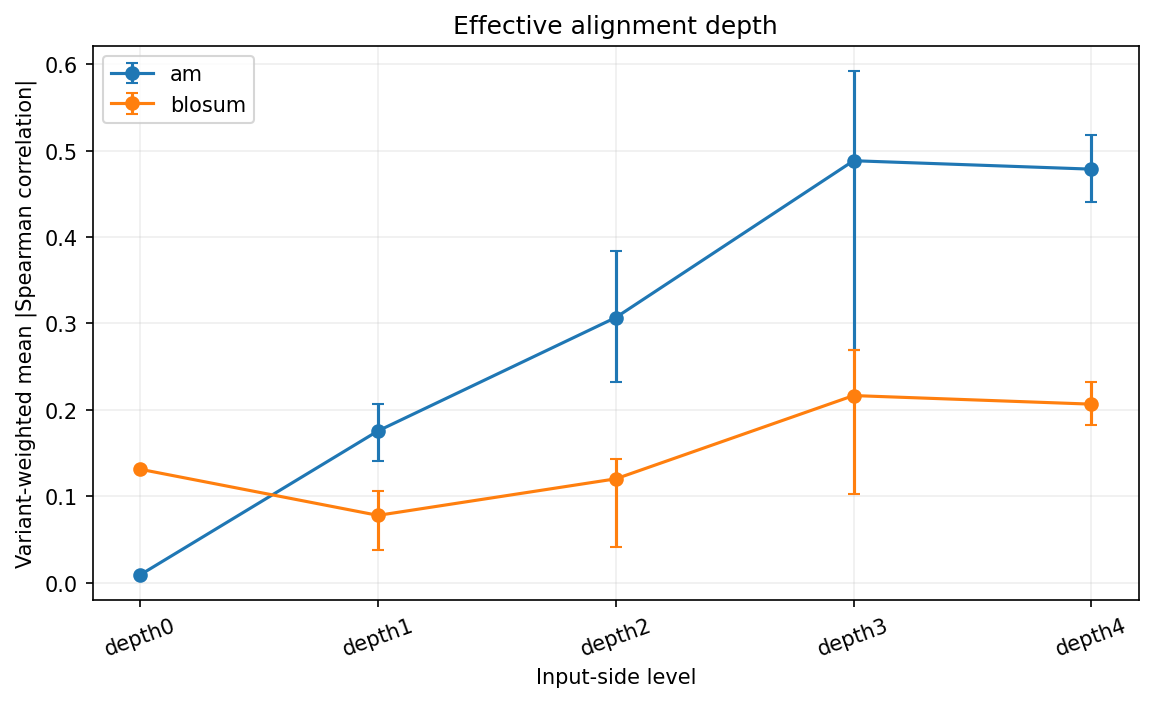

In [9]:
AXIS_NUMBER=3
AXIS='Effective alignment depth'
LEVELS=['depth0', 'depth1', 'depth2', 'depth3', 'depth4']
PREDICTORS=['am', 'blosum']

MIN_VARIANTS=20;B=5000;rng=np.random.default_rng(42)
selectors={
 'insert':lambda d:d.insertion,
 'q0':lambda d:(~d.insertion)&(d.occupancy<=.945),
 'q1':lambda d:(~d.insertion)&(d.occupancy>.945)&(d.occupancy<=.987),
 'q2':lambda d:(~d.insertion)&(d.occupancy>.987)&(d.occupancy<=.998),
 'q3':lambda d:(~d.insertion)&(d.occupancy>.998)&(d.occupancy<=.999),
 'q4':lambda d:(~d.insertion)&(d.occupancy>.999),
 'coarse_hard':lambda d:d.insertion|((~d.insertion)&(d.occupancy<=.9)),
 'coarse_easy':lambda d:(~d.insertion)&(d.occupancy>.9),
 'deep_occ<0.5':lambda d:(~d.insertion)&(d.neff>=200)&(d.occupancy<.5),
 'deep_occ<0.7':lambda d:(~d.insertion)&(d.neff>=200)&(d.occupancy<.7),
 'deep_occ>=0.9':lambda d:(~d.insertion)&(d.neff>=200)&(d.occupancy>=.9)}
for i,(lo,hi) in enumerate(zip([0,2,10,50,200],[2,10,50,200,np.inf])):selectors[f'depth{i}']=lambda d,lo=lo,hi=hi:(~d.insertion)&(d.neff>=lo)&(d.neff<hi)
selected_names=list(dict.fromkeys(LEVELS+['coarse_hard','coarse_easy']))
per_assay=[];signal=[];composition=[]
for level in selected_names:
    subset=panel.loc[selectors[level](panel)]
    residues=subset.drop_duplicates(['accession','position']);counts=residues.accession.value_counts()
    composition.append({'level':level,'residues':len(residues),'proteins':residues.accession.nunique(),'largest_protein_fraction':counts.max()/len(residues) if len(residues) else np.nan,'internal_fraction':1-residues.terminal.mean() if len(residues) else np.nan})
    for aid,g in subset.groupby('assay'):
        if len(g)<MIN_VARIANTS:continue
        full=panel[panel.assay==aid];spread=float(g.fitness.std(ddof=0));full_spread=float(full.fitness.std(ddof=0));signal.append({'level':level,'assay':aid,'protein':g.accession.iloc[0],'n':len(g),'fitness_sd':spread,'relative_spread':spread/full_spread if full_spread>0 else np.nan})
        for score in PREDICTORS:
            d=g.dropna(subset=[score])
            if len(d)<MIN_VARIANTS or d[score].nunique()<2 or d.fitness.nunique()<2:continue
            rho=float(spearmanr(d[score],d.fitness).statistic)
            per_assay.append({'level':level,'assay':aid,'protein':g.accession.iloc[0],'family':g.family.iloc[0],'score':score,'n':len(d),'signed_rho':rho,'abs_rho':abs(rho)})
per_assay=pd.DataFrame(per_assay);signal=pd.DataFrame(signal);composition=pd.DataFrame(composition);rows=[]
for (level,score),d in per_assay.groupby(['level','score']):
    n=d.n.to_numpy(float);values=d.abs_rho.to_numpy();idx=rng.integers(0,len(d),size=(B,len(d)));draws=(n[idx]*values[idx]).sum(1)/n[idx].sum(1);lo,hi=np.quantile(draws,[.025,.975])
    rows.append({'level':level,'score':score,'weighted_abs_rho':np.average(values,weights=n),'mean_abs_rho':values.mean(),'median_abs_rho':np.median(values),'ci_low':lo,'ci_high':hi,'assays':len(d),'proteins':d.protein.nunique(),'variants':int(n.sum())})
curves=pd.DataFrame(rows);signal_summary=signal.groupby('level').agg(assays=('assay','nunique'),median_fitness_sd=('fitness_sd','median'),mean_relative_spread=('relative_spread','mean')).reset_index()
# Within-assay paired comparisons and a family exclusion keep mixture changes visible.
contrasts=[]
for score in PREDICTORS:
    d=per_assay[per_assay.score==score];wide=d.pivot(index='assay',columns='level',values='abs_rho')
    for first,last in [(LEVELS[0],LEVELS[-1]),('coarse_hard','coarse_easy')]:
        if first not in wide or last not in wide:continue
        x=(wide[last]-wide[first]).dropna().to_numpy()
        if len(x):
            draws=np.array([rng.choice(x,len(x),replace=True).mean() for _ in range(B)]);lo,hi=np.quantile(draws,[.025,.975]);contrasts.append({'score':score,'first':first,'last':last,'paired_assays':len(x),'mean_last_minus_first':x.mean(),'ci_low':lo,'ci_high':hi})
contrasts=pd.DataFrame(contrasts);family_controls=per_assay.groupby(['level','score','family']).apply(lambda g:pd.Series({'assays':len(g),'weighted_abs_rho':np.average(g.abs_rho,weights=g.n)}),include_groups=False).reset_index()
display(curves);display(contrasts);display(signal_summary);display(composition);display(family_controls)
fig,ax=plt.subplots(figsize=(9,4.8))
if AXIS_NUMBER==7:
    d=signal_summary.set_index('level').reindex(LEVELS);ax.plot(range(len(LEVELS)),d.mean_relative_spread,marker='o');ax.set(ylabel='Mean within-assay SD / full-assay SD')
else:
    for score in PREDICTORS:
        d=curves[curves.score==score].set_index('level').reindex(LEVELS);y=d.weighted_abs_rho.to_numpy();ax.errorbar(range(len(LEVELS)),y,yerr=np.maximum(0,np.array([y-d.ci_low,d.ci_high-y])),marker='o',capsize=3,label=score)
    ax.set(ylabel='Variant-weighted mean |Spearman correlation|');ax.legend()
ax.set(xticks=range(len(LEVELS)),xticklabels=LEVELS,xlabel='Input-side level',title=AXIS);ax.tick_params(axis='x',labelrotation=20);ax.grid(alpha=.2);show_figure(fig);plt.close(fig)


## 6. Result and decision

The calculated endpoint contrast informs the directional decision. Controls characterize whether the pattern follows experimental signal or shared position difficulty; absolute correlations alone do not establish a model-specific defect.


In [10]:
selected=contrasts[(contrasts.score=='am')&(contrasts['first']==LEVELS[0])&(contrasts['last']==LEVELS[-1])]
if AXIS_NUMBER==7:
    d=signal_summary.set_index('level').reindex(LEVELS);a=d.mean_relative_spread.iloc[0];b=d.mean_relative_spread.iloc[-1]
    decision=('DMS dynamic range is lower in the first than the last occupancy level. Treat reduced experimental signal as a possible contributor to the performance curve; it does not by itself establish a predictor-specific defect.' if a<b else 'The experimental dynamic-range diagnostic does not show lower spread in the first occupancy level. Do not attribute the performance pattern to a simple collapse of DMS spread.')
elif selected.empty:decision='The endpoint comparison has no paired assays meeting the minimum support. Do not claim a supported directional degradation from unmatched pooled levels.'
else:
    x=selected.iloc[0]
    if x.ci_low>0:decision='Retain a directional association: predictive agreement is greater in the final level within the same assays. The displayed references, assay-family composition, residue concentration and DMS-spread controls constrain the interpretation.'
    else:decision='Do not retain a supported directional degradation claim: the paired endpoint interval does not exclude zero in the expected direction.'
print(decision)
for name,table in [('curves',curves),('per_assay',per_assay),('contrasts',contrasts),('signal_by_assay',signal),('signal_summary',signal_summary),('composition',composition),('family_controls',family_controls),('score_join_coverage',coverage),('position_features',position_features)]:table.to_csv(OUTPUT/(name+'.csv'),index=False)
panel.to_csv(OUTPUT/'individual_variants.csv.gz',index=False,compression='gzip')
receipt={'axis':AXIS,'sources':source_receipts,'decision':decision,'host':platform.node(),'rows':len(panel),'assays':panel.assay.nunique(),'bootstrap_replicates':B,'bootstrap_unit':'assay','fresh_alignment_clustering':WEIGHTED,'outputs':{p.name:sha256_file(p) for p in OUTPUT.glob('*.csv*')},'elapsed_seconds':time.time()-STARTED}
(OUTPUT/'execution.json').write_text(json.dumps(receipt,indent=2)+'\n')


Retain a directional association: predictive agreement is greater in the final level within the same assays. The displayed references, assay-family composition, residue concentration and DMS-spread controls constrain the interpretation.


2706